# Huấn luyện mô hình phát hiện gian lận (PaySim)

Notebook này là nguồn duy nhất tạo ra `models/random_forest.pkl` (tên file giữ nguyên để FastAPI không phải sửa; thuật toán thắng cuộc ghi trong metadata).
Chạy từ trên xuống dưới (Run All). Quá trình so sánh và tối ưu siêu tham số có thể mất vài chục phút.

**Quy trình (theo góp ý của hội đồng):**
1. Đọc dữ liệu PaySim đầy đủ, lọc `TRANSFER` và `CASH_OUT`, tạo feature, chia train/validation/test (60/20/20).
2. So sánh **ít nhất 3 mô hình**: Logistic Regression (baseline), Random Forest, XGBoost, và LightGBM (nếu đã cài), với hai cách xử lý mất cân bằng: trọng số lớp và SMOTE.
3. Chọn mô hình theo **F1-Score và ROC-AUC** trên tập validation, báo thêm PR-AUC.
4. Tối ưu siêu tham số cho mô hình được chọn.
5. Chọn ngưỡng trên validation, đánh giá một lần trên test, kiểm tra ablation, lưu mô hình kèm metadata.

**Lưu ý:** file CSV phải là bản đầy đủ (6.362.620 dòng). Không mở và lưu file này bằng Excel vì Excel cắt ở 1.048.576 dòng.

In [1]:
import datetime
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, classification_report, f1_score,
                             precision_recall_curve, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False
    print('Chưa cài lightgbm, bỏ qua mô hình thứ 4 (pip install lightgbm).')

RANDOM_STATE = 42
EXPECTED_SHAPE = (6362620, 11)
SMOTE_RATIO = 0.1     # SMOTE nâng lớp gian lận lên 10% lớp bình thường (đặt 1.0 nếu muốn cân bằng 1:1, tốn RAM và thời gian hơn)
N_ITER = 12           # số tổ hợp siêu tham số thử ở bước tối ưu
N_TUNE = 400_000      # số dòng train dùng cho bước tối ưu siêu tham số

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
DATA_PATH = ROOT / 'data' / 'PS_20174392719_1491204439457_log.csv'
MODEL_PATH = ROOT / 'models' / 'random_forest.pkl'
REPORT_DIR = ROOT / 'reports'
FIG_DIR = REPORT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
print('Thư mục gốc:', ROOT)

Thư mục gốc: D:\University\Đồ án tốt nghiệp\FraudRiskMgmt\fraud-detection-ml


## 1. Đọc dữ liệu

In [2]:
df = pd.read_csv(DATA_PATH)
assert df.shape == EXPECTED_SHAPE, f'File dữ liệu không đầy đủ: {df.shape}. Chép lại bản gốc từ Kaggle, đừng lưu bằng Excel.'
print(df.shape)
df.head()

(6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


## 2. Khám phá dữ liệu

Gian lận: 8,213 / 6,362,620 (0.13%)


,Số fraud,Tổng GD,Tỷ lệ fraud
type,,,
CASH_IN,0,1399284,0.0000
CASH_OUT,4116,2237500,0.0018
DEBIT,0,41432,0.0000
PAYMENT,0,2151495,0.0000
TRANSFER,4097,532909,0.0077


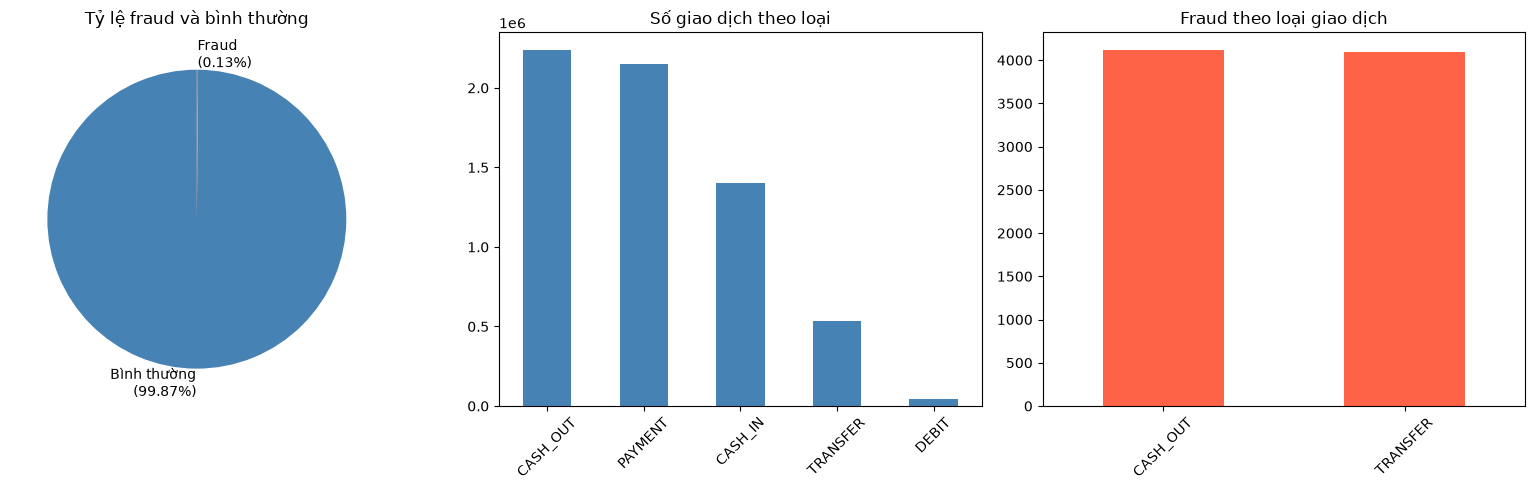

In [3]:
n_fraud = int(df['isFraud'].sum())
print(f'Gian lận: {n_fraud:,} / {len(df):,} ({n_fraud / len(df):.2%})')

by_type = df.groupby('type')['isFraud'].agg(['sum', 'count', 'mean'])
by_type.columns = ['Số fraud', 'Tổng GD', 'Tỷ lệ fraud']
display(by_type.round(4))

counts = df['isFraud'].value_counts().sort_index()
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].pie(counts, colors=['steelblue', 'tomato'], startangle=90,
            labels=[f'Bình thường\n({counts[0] / len(df):.2%})', f'Fraud\n({counts[1] / len(df):.2%})'])
axes[0].set_title('Tỷ lệ fraud và bình thường')
df['type'].value_counts().plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_title('Số giao dịch theo loại')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=45)
df.loc[df['isFraud'] == 1, 'type'].value_counts().plot(kind='bar', ax=axes[2], color='tomato')
axes[2].set_title('Fraud theo loại giao dịch')
axes[2].set_xlabel('')
axes[2].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig(FIG_DIR / '01_overview.png', dpi=150, bbox_inches='tight')
plt.show()

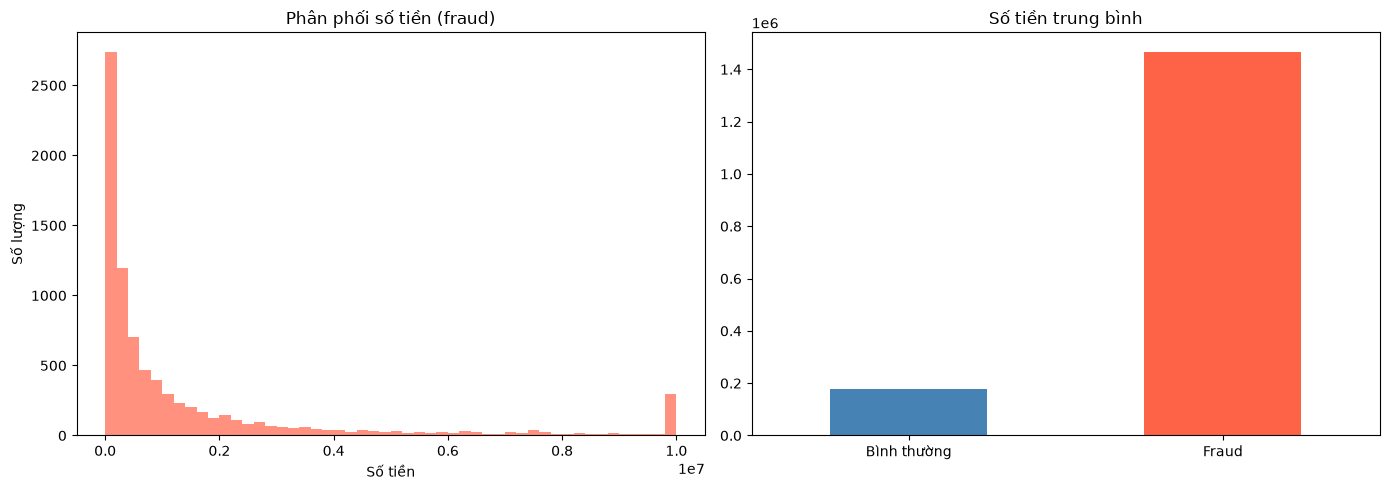

Fraud:
count        8213.00
mean      1467967.30
std       2404252.95
min             0.00
25%        127091.33
50%        441423.44
75%       1517771.48
max      10000000.00
Name: amount, dtype: float64

Bình thường:
count     6354407.00
mean       178197.04
std        596236.98
min             0.01
25%         13368.40
50%         74684.72
75%        208364.76
max      92445516.64
Name: amount, dtype: float64


In [4]:
fraud = df[df['isFraud'] == 1]
normal = df[df['isFraud'] == 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].hist(fraud['amount'], bins=50, color='tomato', alpha=0.7)
axes[0].set_title('Phân phối số tiền (fraud)')
axes[0].set_xlabel('Số tiền')
axes[0].set_ylabel('Số lượng')
df.groupby('isFraud')['amount'].mean().rename({0: 'Bình thường', 1: 'Fraud'}).plot(
    kind='bar', ax=axes[1], color=['steelblue', 'tomato'])
axes[1].set_title('Số tiền trung bình')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / '02_amount_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print('Fraud:'); print(fraud['amount'].describe().round(2))
print('\nBình thường:'); print(normal['amount'].describe().round(2))

## 3. Lọc loại giao dịch và tạo feature

Gian lận trong PaySim chỉ xuất hiện ở `TRANSFER` và `CASH_OUT`, nên mô hình chỉ học hai loại này.
Feature `is_merchant` đã bỏ vì luôn bằng 0 sau khi lọc (tài khoản `M...` chỉ nhận tiền ở giao dịch `PAYMENT`).

Định nghĩa `errorBalance*` phải **giống hệt** ở backend khi suy luận:
- `errorBalanceOrig = oldbalanceOrg - newbalanceOrig - amount`
- `errorBalanceDest = newbalanceDest - oldbalanceDest - amount`

In [5]:
d = df[df['type'].isin(['TRANSFER', 'CASH_OUT'])].copy()
d['hour'] = d['step'] % 24
d['errorBalanceOrig'] = d['oldbalanceOrg'] - d['newbalanceOrig'] - d['amount']
d['errorBalanceDest'] = d['newbalanceDest'] - d['oldbalanceDest'] - d['amount']

assert (d['nameDest'].str[0] == 'M').sum() == 0, 'is_merchant không còn hằng số 0, cần xem lại feature'

FEATURES = ['hour', 'amount', 'errorBalanceOrig', 'errorBalanceDest',
            'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']
X, y = d[FEATURES], d['isFraud']
print(X.shape, int(y.sum()), 'ca gian lận')

(2770409, 8) 8213 ca gian lận


## 4. Chia dữ liệu 60% train, 20% validation, 20% test (phân tầng theo nhãn)

In [6]:
X_tmp, X_test, y_tmp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=RANDOM_STATE)
print('train', X_train.shape, '| val', X_val.shape, '| test', X_test.shape)

train (1662245, 8) | val (554082, 8) | test (554082, 8)


## 5. So sánh các mô hình

**Vì sao chọn các thuật toán này (dùng cho đề cương và báo cáo):**
- Dữ liệu giao dịch ngân hàng là dạng bảng (tabular). Với dạng dữ liệu này, các mô hình dựa trên cây (Random Forest, XGBoost, LightGBM) thường cho kết quả tốt nhất.
- Logistic Regression là mô hình cơ sở (baseline) đơn giản, dễ giải thích, dùng để chứng minh mô hình phức tạp hơn thật sự cần thiết.
- Cả bốn đều cho điểm xác suất và hỗ trợ giải thích theo mức độ quan trọng của feature.

**Hai cách xử lý mất cân bằng lớp được so sánh:** trọng số lớp (`class_weight` / `scale_pos_weight`) và SMOTE
(chỉ áp dụng trên tập train, nằm trong pipeline nên không rò rỉ sang validation và test).

**Tiêu chí chọn:** F1-Score (ở ngưỡng tối ưu của từng mô hình trên validation), rồi ROC-AUC. PR-AUC báo cáo thêm vì ROC-AUC dễ cao giả tạo khi dữ liệu mất cân bằng.

In [7]:
MODEL_NAMES = ['Logistic Regression', 'Random Forest', 'XGBoost'] + (['LightGBM'] if HAS_LGBM else [])
STRATEGIES = ['Trọng số lớp', 'SMOTE']


def build(name, strategy, y_):
    weighted = strategy == 'Trọng số lớp'
    spw = (y_ == 0).sum() / (y_ == 1).sum() if weighted else 1.0
    if name == 'Logistic Regression':
        return Pipeline([('scaler', StandardScaler()),
                         ('clf', LogisticRegression(max_iter=300, class_weight='balanced' if weighted else None,
                                                    random_state=RANDOM_STATE))])
    if name == 'Random Forest':
        return RandomForestClassifier(n_estimators=150, min_samples_leaf=2, max_samples=0.3, n_jobs=-1,
                                      class_weight='balanced_subsample' if weighted else None,
                                      random_state=RANDOM_STATE)
    if name == 'XGBoost':
        return XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, tree_method='hist',
                             scale_pos_weight=spw, n_jobs=-1, random_state=RANDOM_STATE)
    if name == 'LightGBM':
        return LGBMClassifier(n_estimators=300, learning_rate=0.1, num_leaves=31, scale_pos_weight=spw,
                              n_jobs=-1, random_state=RANDOM_STATE, verbose=-1)
    raise ValueError(name)


def make_pipeline(name, strategy, y_):
    steps = [('model', build(name, strategy, y_))]
    if strategy == 'SMOTE':
        steps.insert(0, ('smote', SMOTE(sampling_strategy=SMOTE_RATIO, random_state=RANDOM_STATE)))
    return ImbPipeline(steps)


def evaluate(pipe, label_model, label_strategy, seconds):
    s = pipe.predict_proba(X_val)[:, 1]
    p_, r_, t_ = precision_recall_curve(y_val, s)
    f1_ = 2 * p_[:-1] * r_[:-1] / (p_[:-1] + r_[:-1] + 1e-8)
    i = int(np.argmax(f1_))
    row = {'Mô hình': label_model, 'Xử lý mất cân bằng': label_strategy,
           'Precision': p_[i], 'Recall': r_[i], 'F1': f1_[i],
           'ROC-AUC': roc_auc_score(y_val, s), 'PR-AUC': average_precision_score(y_val, s),
           'Ngưỡng tối ưu': t_[i], 'Thời gian (giây)': seconds}
    return row, s

In [8]:
rows, val_scores, fitted = [], {}, {}
for strategy in STRATEGIES:
    for name in MODEL_NAMES:
        t0 = time.time()
        pipe = make_pipeline(name, strategy, y_train).fit(X_train, y_train)
        row, s = evaluate(pipe, name, strategy, round(time.time() - t0, 1))
        rows.append(row)
        val_scores[(name, strategy)] = s
        fitted[(name, strategy)] = pipe
        print(f'{name} | {strategy}: F1={row["F1"]:.4f}, ROC-AUC={row["ROC-AUC"]:.4f}, {row["Thời gian (giây)"]}s')

results = pd.DataFrame(rows).sort_values(['F1', 'ROC-AUC'], ascending=False).reset_index(drop=True)
results.to_csv(REPORT_DIR / 'model_comparison.csv', index=False)
display(results.round(4))

best_name, best_strategy = results.loc[0, 'Mô hình'], results.loc[0, 'Xử lý mất cân bằng']
print(f'Mô hình dẫn đầu (theo F1 rồi ROC-AUC): {best_name} + {best_strategy}')

Logistic Regression | Trọng số lớp: F1=0.5677, ROC-AUC=0.9758, 3.4s
Random Forest | Trọng số lớp: F1=0.9982, ROC-AUC=0.9987, 47.2s
XGBoost | Trọng số lớp: F1=0.9622, ROC-AUC=0.9984, 15.2s
LightGBM | Trọng số lớp: F1=0.0302, ROC-AUC=0.9031, 5.4s
Logistic Regression | SMOTE: F1=0.6232, ROC-AUC=0.9790, 2.2s
Random Forest | SMOTE: F1=0.9979, ROC-AUC=0.9990, 54.3s
XGBoost | SMOTE: F1=0.9593, ROC-AUC=0.9982, 19.5s
LightGBM | SMOTE: F1=0.3028, ROC-AUC=0.9423, 10.9s


,Mô hình,Xử lý mất cân bằng,Precision,Recall,F1,ROC-AUC,PR-AUC,Ngưỡng tối ưu,Thời gian (giây)
0,Random Forest,Trọng số lớp,0.9994,0.9970,0.9982,0.9987,0.9976,0.3794,47.2
1,Random Forest,SMOTE,0.9982,0.9976,0.9979,0.9990,0.9977,0.6398,54.3
2,XGBoost,Trọng số lớp,0.9567,0.9677,0.9622,0.9984,0.9938,0.9867,15.2
3,XGBoost,SMOTE,0.9378,0.9817,0.9593,0.9982,0.9931,0.7205,19.5
4,Logistic Regression,SMOTE,0.7462,0.5350,0.6232,0.9790,0.6255,0.9474,2.2
5,Logistic Regression,Trọng số lớp,0.7747,0.4480,0.5677,0.9758,0.5493,0.9997,3.4
6,LightGBM,SMOTE,0.1822,0.8965,0.3028,0.9423,0.1636,1.0000,10.9
7,LightGBM,Trọng số lớp,0.0153,0.9970,0.0302,0.9031,0.0153,1.0000,5.4


Mô hình dẫn đầu (theo F1 rồi ROC-AUC): Random Forest + Trọng số lớp


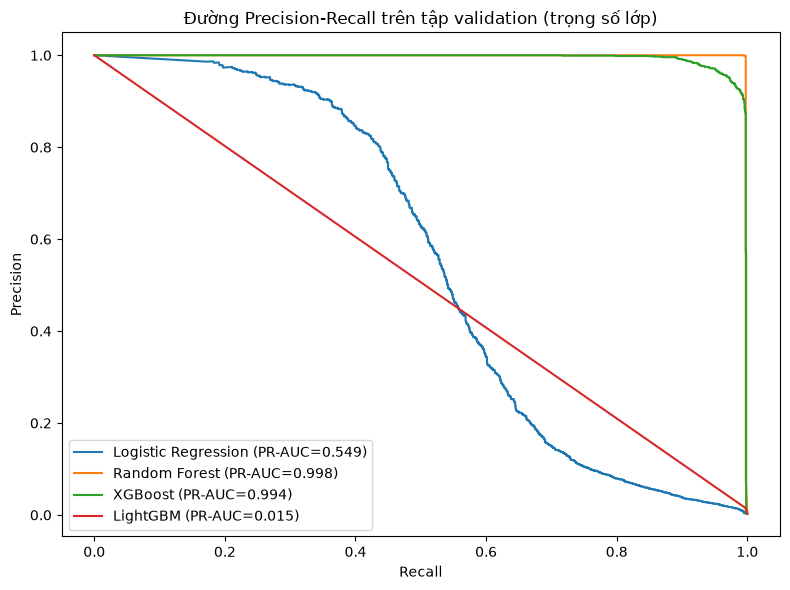

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
for name in MODEL_NAMES:
    p_, r_, _ = precision_recall_curve(y_val, val_scores[(name, 'Trọng số lớp')])
    ax.plot(r_, p_, label=f'{name} (PR-AUC={average_precision_score(y_val, val_scores[(name, "Trọng số lớp")]):.3f})')
ax.set_xlabel('Recall')
ax.set_ylabel('Precision')
ax.set_title('Đường Precision-Recall trên tập validation (trọng số lớp)')
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / '03_model_pr_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 6. Tối ưu siêu tham số cho mô hình dẫn đầu

Tìm kiếm ngẫu nhiên có kiểm tra chéo 3 lần trên một mẫu phân tầng của tập train (để chạy nhanh), chấm điểm bằng PR-AUC.
Nếu mô hình dẫn đầu dùng SMOTE thì SMOTE nằm trong pipeline, chỉ áp dụng trên phần train của từng lần kiểm tra chéo.
Sau đó huấn luyện lại bằng bộ tham số tốt nhất trên toàn bộ tập train và so với bản chưa tối ưu.

In [10]:
PARAMS = {
    'Logistic Regression': {'model__clf__C': [0.01, 0.1, 1, 10, 100]},
    'Random Forest': {'model__n_estimators': [100, 150, 250], 'model__max_depth': [None, 12, 20],
                      'model__min_samples_leaf': [1, 2, 5], 'model__max_features': ['sqrt', 0.5],
                      'model__max_samples': [0.2, 0.3, 0.5]},
    'XGBoost': {'model__n_estimators': [200, 300, 500], 'model__max_depth': [4, 6, 8],
                'model__learning_rate': [0.05, 0.1, 0.2], 'model__subsample': [0.7, 1.0],
                'model__colsample_bytree': [0.7, 1.0], 'model__min_child_weight': [1, 5]},
    'LightGBM': {'model__n_estimators': [200, 300, 500], 'model__num_leaves': [15, 31, 63],
                 'model__learning_rate': [0.05, 0.1, 0.2], 'model__subsample': [0.7, 1.0],
                 'model__colsample_bytree': [0.7, 1.0], 'model__min_child_samples': [10, 20, 50]},
}

if len(X_train) > N_TUNE:
    X_tune, _, y_tune, _ = train_test_split(X_train, y_train, train_size=N_TUNE, stratify=y_train, random_state=RANDOM_STATE)
else:
    X_tune, y_tune = X_train, y_train
print('Mẫu tối ưu:', X_tune.shape, int(y_tune.sum()), 'ca gian lận')

t0 = time.time()
search = RandomizedSearchCV(make_pipeline(best_name, best_strategy, y_tune), PARAMS[best_name], n_iter=N_ITER,
                            scoring='average_precision', cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                            n_jobs=1, random_state=RANDOM_STATE, refit=False, verbose=1)
search.fit(X_tune, y_tune)
best_params = search.best_params_
print(f'Tìm kiếm xong sau {time.time() - t0:.0f}s. Tham số tốt nhất:', best_params, '| PR-AUC CV =', round(search.best_score_, 4))

t0 = time.time()
tuned = make_pipeline(best_name, best_strategy, y_train).set_params(**best_params).fit(X_train, y_train)
row_tuned, s_tuned = evaluate(tuned, best_name, best_strategy + ' (đã tối ưu)', round(time.time() - t0, 1))
row_base = results.iloc[0].to_dict()

compare = pd.DataFrame([{**row_base, 'Xử lý mất cân bằng': best_strategy + ' (mặc định)'}, row_tuned])
display(compare.round(4))

use_tuned = row_tuned['F1'] >= row_base['F1']
final_pipe = tuned if use_tuned else fitted[(best_name, best_strategy)]
final_params = best_params if use_tuned else {}
print('Dùng bản', 'đã tối ưu' if use_tuned else 'mặc định')
best = final_pipe.named_steps['model']

Mẫu tối ưu: (400000, 8) 1186 ca gian lận
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Tìm kiếm xong sau 232s. Tham số tốt nhất: {'model__n_estimators': 150, 'model__min_samples_leaf': 1, 'model__max_samples': 0.5, 'model__max_features': 'sqrt', 'model__max_depth': None} | PR-AUC CV = 0.9958


,Mô hình,Xử lý mất cân bằng,Precision,Recall,F1,ROC-AUC,PR-AUC,Ngưỡng tối ưu,Thời gian (giây)
0,Random Forest,Trọng số lớp (mặc định),0.9994,0.997,0.9982,0.9987,0.9976,0.3794,47.2
1,Random Forest,Trọng số lớp (đã tối ưu),0.9994,0.997,0.9982,0.9988,0.9976,0.3200,54.9


Dùng bản đã tối ưu


## 7. Chọn ngưỡng trên validation, đánh giá một lần trên test

Ngưỡng chọn bằng F1 lớn nhất trên **validation** (không dùng test để chọn). Bảng dải điểm và phân vị số tiền gian lận
là căn cứ để đặt `RiskPolicy` ở backend.

In [11]:
s_val = best.predict_proba(X_val)[:, 1]
p, r, t = precision_recall_curve(y_val, s_val)
f1 = 2 * p[:-1] * r[:-1] / (p[:-1] + r[:-1] + 1e-8)
thr = float(t[np.argmax(f1)])
print(f'Mô hình: {best_name} | ngưỡng chọn trên validation: {thr:.4f}')

bands = pd.cut(s_val, [0, .3, .5, .75, .85, .95, 1.0001], right=False)
print(pd.crosstab(bands, y_val.values, rownames=['dải điểm'], colnames=['isFraud']))

s_test = best.predict_proba(X_test)[:, 1]
pred_test = (s_test >= thr).astype(int)
print(classification_report(y_test, pred_test, digits=4))
print('ROC-AUC test:', round(roc_auc_score(y_test, s_test), 4), '| PR-AUC test:', round(average_precision_score(y_test, s_test), 4))

print('Phân vị số tiền của các ca gian lận:')
print(d.loc[d['isFraud'] == 1, 'amount'].describe(percentiles=[.25, .5, .75, .9]).round(0))

Mô hình: Random Forest | ngưỡng chọn trên validation: 0.3200
isFraud            0     1
dải điểm                  
[0.0, 0.3)    552438     5
[0.3, 0.5)         0     2
[0.5, 0.75)        1     9
[0.75, 0.85)       0    17
[0.85, 0.95)       0   113
[0.95, 1.0)        0  1497
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000    552439
           1     0.9988    0.9963    0.9976      1643

    accuracy                         1.0000    554082
   macro avg     0.9994    0.9982    0.9988    554082
weighted avg     1.0000    1.0000    1.0000    554082

ROC-AUC test: 0.9985 | PR-AUC test: 0.997
Phân vị số tiền của các ca gian lận:
count        8213.0
mean      1467967.0
std       2404253.0
min             0.0
25%        127091.0
50%        441423.0
75%       1517771.0
90%       4521724.0
max      10000000.0
Name: amount, dtype: float64


## 8. Kiểm tra độ phụ thuộc vào feature và kiểm tra theo thời gian

Dùng XGBoost (tham số mặc định) cho nhanh, nên con số chỉ để so sánh các bộ feature với nhau.

In [12]:
sets = {
    'đủ 8 feature': FEATURES,
    'bỏ 2 errorBalance': ['hour', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest'],
    'chỉ hour + amount': ['hour', 'amount'],
}
for name, cols in sets.items():
    m = build('XGBoost', 'Trọng số lớp', y_train).fit(X_train[cols], y_train)
    print(f'{name}: PR-AUC validation = {average_precision_score(y_val, m.predict_proba(X_val[cols])[:, 1]):.4f}')

cut = d['step'].quantile(0.8)
tr, te = d[d['step'] <= cut], d[d['step'] > cut]
m = build('XGBoost', 'Trọng số lớp', tr['isFraud']).fit(tr[FEATURES], tr['isFraud'])
print(f'Theo thời gian (học 80% bước đầu, thử 20% bước sau): PR-AUC = '
      f'{average_precision_score(te["isFraud"], m.predict_proba(te[FEATURES])[:, 1]):.4f}')

đủ 8 feature: PR-AUC validation = 0.9938
bỏ 2 errorBalance: PR-AUC validation = 0.9457
chỉ hour + amount: PR-AUC validation = 0.2221
Theo thời gian (học 80% bước đầu, thử 20% bước sau): PR-AUC = 0.9970


## 9. Lưu mô hình

Tên file giữ nguyên `random_forest.pkl` để FastAPI không phải sửa đường dẫn. Thuật toán thắng cuộc, cách xử lý mất cân bằng,
siêu tham số, bảng so sánh và chỉ số test nằm trong metadata bên trong file.

In [13]:
model_package = {
    'model': best,
    'features': FEATURES,
    'threshold': thr,
    'model_name': best_name,
    'imbalance_strategy': best_strategy,
    'hyperparameters': {k: str(v) for k, v in final_params.items()},
    'version': '1.0.0',
    'dataset': f'PaySim đầy đủ, {len(df):,} dòng, {n_fraud:,} ca gian lận',
    'random_state': RANDOM_STATE,
    'trained_at': datetime.datetime.now().isoformat(timespec='seconds'),
    'train_rows': int(len(X_train)),
    'sklearn_version': sklearn.__version__,
    'threshold_selection': 'F1 lớn nhất trên tập validation (20%)',
    'comparison_val': results.round(4).to_dict('records'),
    'metrics_test': {
        'precision': float(precision_score(y_test, pred_test)),
        'recall': float(recall_score(y_test, pred_test)),
        'f1': float(f1_score(y_test, pred_test)),
        'roc_auc': float(roc_auc_score(y_test, s_test)),
        'pr_auc': float(average_precision_score(y_test, s_test)),
        'test_rows': int(len(y_test)),
        'test_frauds': int(y_test.sum()),
    },
}
joblib.dump(model_package, MODEL_PATH, compress=3)

pkg = joblib.load(MODEL_PATH)
s_check = pkg['model'].predict_proba(X_test[pkg['features']])[:, 1]
print(f'Đã lưu {MODEL_PATH.name}: {MODEL_PATH.stat().st_size / 1024 / 1024:.1f} MB | '
      f'nạp lại khớp điểm: {np.allclose(s_check, s_test)}')
print(pkg['metrics_test'])

Đã lưu random_forest.pkl: 1.1 MB | nạp lại khớp điểm: True
{'precision': 0.9987797437461867, 'recall': 0.9963481436396835, 'f1': 0.9975624619134674, 'roc_auc': 0.9984740187347169, 'pr_auc': 0.9969628435678082, 'test_rows': 554082, 'test_frauds': 1643}


In [14]:
cols = ['step','type','amount','nameOrig','oldbalanceOrg','newbalanceOrig',
        'nameDest','oldbalanceDest','newbalanceDest','isFraud']

score = pd.Series(s_test, index=X_test.index)
test_rows = df.loc[X_test.index, cols].copy()
test_rows['model_score'] = score.round(4)
is_f = test_rows['isFraud'] == 1
test_rows['demo_tag'] = np.select(
    [is_f & (score < thr), is_f & (score < 0.85), is_f, (~is_f) & (score >= thr)],
    ['missed_fraud', 'fraud_mid', 'fraud_high', 'false_positive'], default='normal')

special = test_rows[test_rows['demo_tag'] != 'normal']                      # toàn bộ fraud và ca bất thường
normal = test_rows[test_rows['demo_tag'] == 'normal'].sample(20000, random_state=RANDOM_STATE)
others = df[~df['type'].isin(['TRANSFER', 'CASH_OUT'])][cols].sample(5000, random_state=RANDOM_STATE)
others = others.assign(model_score=np.nan, demo_tag='rule_only')

out = pd.concat([special, normal, others]).sample(frac=1, random_state=RANDOM_STATE)
out.to_csv(ROOT / 'data' / 'simulator_source.csv', index=False)
print(out['demo_tag'].value_counts())

demo_tag
normal            20000
rule_only          5000
fraud_high         1620
fraud_mid            17
missed_fraud          6
false_positive        2
Name: count, dtype: int64


In [15]:
mid = out[out['demo_tag'] == 'fraud_mid']
print((mid['amount'] >= 1_500_000).value_counts())

amount
False    16
True      1
Name: count, dtype: int64


In [17]:
from sklearn.base import clone

cut = d['step'].quantile(0.8)
tr, te = d[d['step'] <= cut], d[d['step'] > cut]
m = clone(best).fit(tr[FEATURES], tr['isFraud'])
s = m.predict_proba(te[FEATURES])[:, 1]
print('RF theo thời gian: PR-AUC =', round(average_precision_score(te['isFraud'], s), 4),
      '| F1 @thr =', round(f1_score(te['isFraud'], s >= thr), 4))

RF theo thời gian: PR-AUC = 1.0 | F1 @thr = 0.9996


In [19]:
pkg = joblib.load(MODEL_PATH)
labels = {'errorBalanceOrig': 'Sai lệch số dư nguồn', 'oldbalanceOrg': 'Số dư nguồn trước GD',
          'newbalanceOrig': 'Số dư nguồn sau GD', 'newbalanceDest': 'Số dư đích sau GD',
          'oldbalanceDest': 'Số dư đích trước GD', 'amount': 'Số tiền giao dịch',
          'errorBalanceDest': 'Sai lệch số dư đích', 'hour': 'Giờ giao dịch'}
hints = {'errorBalanceOrig': 'Số dư trước − số dư sau − số tiền',
         'errorBalanceDest': 'Số dư sau − số dư trước − số tiền'}
imp = dict(zip(pkg['features'], pkg['model'].feature_importances_))
for k, v in sorted(imp.items(), key=lambda kv: -kv[1]):
    h = f", hint: '{hints[k]}'" if k in hints else ''
    print(f"  {{ key: '{k}', label: '{labels[k]}', importance: {v:.4f}{h} }},")

  { key: 'errorBalanceOrig', label: 'Sai lệch số dư nguồn', importance: 0.4518, hint: 'Số dư trước − số dư sau − số tiền' },
  { key: 'oldbalanceOrg', label: 'Số dư nguồn trước GD', importance: 0.1959 },
  { key: 'newbalanceOrig', label: 'Số dư nguồn sau GD', importance: 0.1074 },
  { key: 'newbalanceDest', label: 'Số dư đích sau GD', importance: 0.0799 },
  { key: 'amount', label: 'Số tiền giao dịch', importance: 0.0513 },
  { key: 'errorBalanceDest', label: 'Sai lệch số dư đích', importance: 0.0475, hint: 'Số dư sau − số dư trước − số tiền' },
  { key: 'oldbalanceDest', label: 'Số dư đích trước GD', importance: 0.0340 },
  { key: 'hour', label: 'Giờ giao dịch', importance: 0.0323 },
